# 12. Ligand-family training support

Cytokines from the same ligand family may trigger related biological signals. The audit grouped the Parse perturbations by how well their ligand families were represented in training and checked whether greater family support predicted better responses.

**Original agent determination:** Higher same-family support did not improve accuracy. The observed direction reversed.

This notebook reconstructs the June primary run from its original downloads, split files, processing code and saved agent decisions. STATE was evaluated through the official scored-output repositories in that run.

**Portable input setup.** Install `../requirements.txt` in a Python3.11 environment. The first code cell restores the exact offline payloads included in this checkout, verifies their hashes, and then runs the original scored-output analysis. No model inference is performed. Historical saved curves remain visible; a clean run rebuilds its own `computed/` tables. See `../README.md`.

In [1]:
from pathlib import Path
import sys, json
root=next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'recovered_pipeline.py').is_file())
sys.path.insert(0,str(root))
import pandas as pd
from IPython.display import display, Markdown
from state_inputs import ensure_inputs
print(ensure_inputs())
import recovered_pipeline as rp
import notebook_support as ns


{'profile': 'default', 'verified_files': 226, 'assets': [{'asset': 'state-historical-comparison-tables.tar.gz', 'members': 25, 'source': 'verified_existing_inputs'}, {'asset': 'state-official-score-cache.tar.gz', 'members': 193, 'source': 'verified_existing_inputs'}, {'asset': 'state-historical-annotations.tar.gz', 'members': 8, 'source': 'verified_existing_inputs'}], 'new_model_inference': False}


Matplotlib is building the font cache; this may take a moment.


## Original acquisition and inputs

The original downloader and processing scripts are preserved unchanged under `original/`. The replay resolves their downloads to the recovered cache at the recorded repository revisions, so no current dataset replaces the original bytes. Original downloads, processing and plotting are separate visible steps below.

In [2]:
verification=rp.run_stage('parse')
ns.show_acquisition('parse')


,repo,revision
0,arcinstitute/ST-HVG-Tahoe,ca6b751972493f8448e3256d1340ae70ad43e1e7
1,arcinstitute/ST-SE-Tahoe,03b1971d7cc93a7535fd2e957c6948dba267378b
2,arcinstitute/ST-HVG-Replogle,bb6a9562cbbf1fd152df14cc53b4cc7517c77175
3,arcinstitute/ST-SE-Replogle,e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c
4,arcinstitute/ST-HVG-Parse,827df657cd87063026d2abefd73e99036755ac1b
5,arcinstitute/ST-SE-Parse,fa458ffda8690c5c5bdff080dfdc46b46713043b
6,tahoebio/Tahoe-100M,2dc57900b7981cfcf5e211527169a0b006546a95


Original evaluation used official scored CSVs. The replay loads the original cached bytes at these revisions.
All 55 score filenames and the three metadata downloads are in computed/initial/artifacts/download_revisions.json.
Initial acquisition implementation: original/state_generalizability_20260602_single_controller/scripts/run_state_spectra_audit.py
Annotation snapshots and split inputs: original/state_generalizability_continued_20260603/external and original/state_generalizability_20260602_single_controller/external/state/state_preprint_toml_files.


,source,original_download_URL
0,GOA,https://current.geneontology.org/annotations/g...
1,GO_basic,https://current.geneontology.org/ontology/go-b...
2,WikiPathways,https://data.wikipathways.org/current/gmt/wiki...
3,KEGG_list_hsa,https://rest.kegg.jp/list/hsa
4,KEGG_list_pathway,https://rest.kegg.jp/list/pathway/hsa
5,KEGG_link_pathway,https://rest.kegg.jp/link/pathway/hsa


## Original processing code

These are the original functions used for this analysis. `recovered_pipeline.py` changes their filesystem destinations and uses the original cached downloads; it writes regenerated products only to `computed/`. Set `force=True` in `run_stage` to recompute this stage after its prerequisites.

In [3]:
ns.show_code('parse',12)

/opt/homebrew/anaconda3/envs/fleming/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


```python
def ligand_family(name: str) -> str:
    s = norm_ligand(name)
    if not s:
        return ""
    if s.startswith("il-") or s.startswith("il"):
        m = re.match(r"il-?(\d+)", s)
        if m:
            return f"interleukin-{m.group(1)}"
        return "interleukin"
    if s.startswith("ifn"):
        if "beta" in s:
            return "interferon-beta"
        if "gamma" in s:
            return "interferon-gamma"
        if "alpha" in s:
            return "interferon-alpha"
        if "lambda" in s:
            return "interferon-lambda"
        if "omega" in s:
            return "interferon-omega"
        return "interferon"
    if any(k in s for k in ["tnf", "trail", "light", "tl1a", "tweak", "4-1bbl", "cd27l", "cd30l", "gitr"]):
        return "tnf-superfamily"
    if any(k in s for k in ["fgf", "egf", "hgf", "vegf", "igf"]):
        return "growth-factor"
    if any(k in s for k in ["g-csf", "gm-csf", "m-csf", "flt3l", "scf"]):
        return "colony-stem-factor"
    if any(k in s for k in ["c5a", "leptin", "osm", "lif", "prl", "epo", "adfs", "adsf"]):
        return "other-cytokine"
    return s.split("-")[0]

```

```python
def infer_parse_train_sets(df: pd.DataFrame, split_specs: dict[str, dict[str, set[str]]]) -> dict[str, set[str]]:
    all_by_context: dict[str, set[str]] = {}
    z = df[(df["dataset_family"] == "Parse-PBMC") & (df["protocol"] == "zeroshot")]
    for context, sub in z.groupby("context"):
        all_by_context[str(context)] = {norm_ligand(x) for x in sub["perturbation"].dropna() if norm_ligand(x)}
    train_by_context = {}
    for context, ligands in all_by_context.items():
        spec = split_specs.get(context, {"test": set(), "val": set()})
        train_by_context[context] = set(ligands) - set(spec.get("test", set())) - set(spec.get("val", set()))
    return train_by_context

```

```python
def run_parse_family_axis(df: pd.DataFrame) -> dict[str, object]:
    specs = load_parse_tomls()
    train_by_context = infer_parse_train_sets(df, specs)
    sub = df[(df["dataset_family"] == "Parse-PBMC") & (df["protocol"] == "fewshot")].copy()
    sub["ligand_norm"] = sub["perturbation"].map(norm_ligand)
    sub["ligand_family"] = sub["ligand_norm"].map(ligand_family)
    rows = []
    for idx, row in sub.iterrows():
        ctx = str(row["context"])
        fam = row["ligand_family"]
        train = train_by_context.get(ctx, set())
        train_fams = Counter(ligand_family(x) for x in train)
        support = train_fams.get(fam, 0)
        rows.append(
            {
                "row_index": idx,
                "parse_train_ligand_count": len(train),
                "parse_ligand_family": fam,
                "parse_family_train_count": support,
                "parse_family_support_fraction": support / len(train) if train else 0.0,
            }
        )
    feat = pd.DataFrame(rows).set_index("row_index")
    sub = sub.join(feat)
    # Freeze a simple prospective support axis; confirmation is alternate cell
    # types from discovery.
    discovery = {"B_Intermediate_Memory", "B_Naive", "Plasmablast"}
    confirmation = {"CD4_Memory", "CD14_Mono"}
    sub["spectra_subset"] = np.where(sub["context"].isin(discovery), "discovery_b_cells_plasmablast", "confirmation_t_mono")
    sub = sub[sub["context"].isin(discovery | confirmation)].copy()
    q = sub[sub["spectra_subset"] == "discovery_b_cells_plasmablast"]["parse_family_train_count"].quantile([0.33, 0.66]).to_dict()
    cps = [float(q[0.33]), float(q[0.66]), float("inf")]
    sub["parse_family_support_level"] = assign_levels_by_cutpoints(
        sub["parse_family_train_count"], cps, ["L1_low", "L2_mid", "L3_high"]
    )
    sub.to_csv(READY / "parse_fewshot_ligand_family_support_examples.csv", index=False)
    freeze = {
        "axis_id": "STATE_PARSE_LIGAND_FAMILY_SUPPORT_V1",
        "status": "frozen_before_confirmation",
        "unit": "Parse-PBMC few-shot ligand perturbation in target cell type and representation",
        "similarity": "Count of same prospective ligand/cytokine family perturbations in same-context training set",
        "direction": "STATE performance should degrade as same-family training support decreases",
        "discovery_contexts": sorted(discovery),
        "confirmation_contexts": sorted(confirmation),
        "target_metric": PRIMARY_METRIC,
        "cutpoints_from_discovery": {"<=q33": cps[0], "<=q66": cps[1], ">q66": "L3_high"},
    }
    (ART / "parse_ligand_family_axis_freeze.json").write_text(json.dumps(freeze, indent=2))
    levels = summarize_levels(
        sub.rename(columns={"ligand_norm": "gene_symbol_canonical"}),
        "parse_family_support_level",
        "parse_family_train_count",
        [PRIMARY_METRIC, *SECONDARY_METRICS],
    )
    levels.to_csv(ART / "spc_parse_fewshot_ligand_family_support.csv", index=False)
    trends = trends_from_levels(levels, PRIMARY_METRIC)
    trends.to_csv(ART / "spc_parse_fewshot_ligand_family_support_trends.csv", index=False)
    return {"freeze": freeze, "levels": levels.to_dict(orient="records"), "trends": trends.to_dict(orient="records")}

```

## Recomputed sample membership, values and result

In [4]:
display(verification)

{'comparison': {'rows': 558,
  'differences': {'parse_train_ligand_count': 0,
   'parse_family_train_count': 0,
   'parse_family_support_fraction': 0,
   'parse_family_support_level': 0},
  'all_match': True},
 'freeze': {'axis_id': 'STATE_PARSE_LIGAND_FAMILY_SUPPORT_V1',
  'status': 'frozen_before_confirmation',
  'unit': 'Parse-PBMC few-shot ligand perturbation in target cell type and representation',
  'similarity': 'Count of same prospective ligand/cytokine family perturbations in same-context training set',
  'direction': 'STATE performance should degrade as same-family training support decreases',
  'discovery_contexts': ['B_Intermediate_Memory', 'B_Naive', 'Plasmablast'],
  'confirmation_contexts': ['CD14_Mono', 'CD4_Memory'],
  'target_metric': 'overlap_at_N',
  'cutpoints_from_discovery': {'<=q33': 0.0, '<=q66': 0.0, '>q66': 'L3_high'}}}

{'rows': 8,
 'differences': {'n_rows': 0,
  'similarity_mean': 0,
  'overlap_at_N_mean': 0,
  'de_sig_genes_recall_mean': 0,
  'pearson_delta_mean': 0},
 'all_match': True}

,spectra_subset,representation,level,level_order,n_rows,n_unique_contexts,n_unique_perturbations,similarity_mean,similarity_min,similarity_max,overlap_at_N_mean,overlap_at_N_median,overlap_at_N_std,de_sig_genes_recall_mean,de_sig_genes_recall_median,de_sig_genes_recall_std,pearson_delta_mean,pearson_delta_median,pearson_delta_std
0,confirmation_t_mono,HVG,L1_low,1,90,2,45,0.0,0.0,0.0,0.504313,0.524823,0.172975,0.691503,0.675044,0.093619,0.853997,0.880657,0.100644
1,confirmation_t_mono,HVG,L3_high,3,34,2,17,1.0,1.0,1.0,0.447836,0.495482,0.171431,0.643764,0.635875,0.089590,0.837239,0.867052,0.120964
2,confirmation_t_mono,SE,L1_low,1,45,1,45,0.0,0.0,0.0,0.647887,0.641770,0.087868,0.691674,0.682171,0.087603,0.831736,0.847404,0.083230
3,confirmation_t_mono,SE,L3_high,3,17,1,17,1.0,1.0,1.0,0.609251,0.600282,0.082548,0.645560,0.662937,0.081171,0.807389,0.837798,0.128365
4,discovery_b_cells_plasmablast,HVG,L1_low,1,135,3,45,0.0,0.0,0.0,0.246921,0.268571,0.185468,0.363655,0.382796,0.223682,0.619236,0.753389,0.283232
5,discovery_b_cells_plasmablast,HVG,L3_high,3,51,3,17,1.0,1.0,1.0,0.224560,0.250000,0.171530,0.345935,0.371571,0.205746,0.592215,0.752709,0.301600
6,discovery_b_cells_plasmablast,SE,L1_low,1,135,3,45,0.0,0.0,0.0,0.277602,0.301471,0.202315,0.386612,0.439423,0.249029,0.615353,0.740221,0.288887
7,discovery_b_cells_plasmablast,SE,L3_high,3,51,3,17,1.0,1.0,1.0,0.250604,0.260355,0.177103,0.356466,0.350000,0.203940,0.569191,0.720011,0.309812


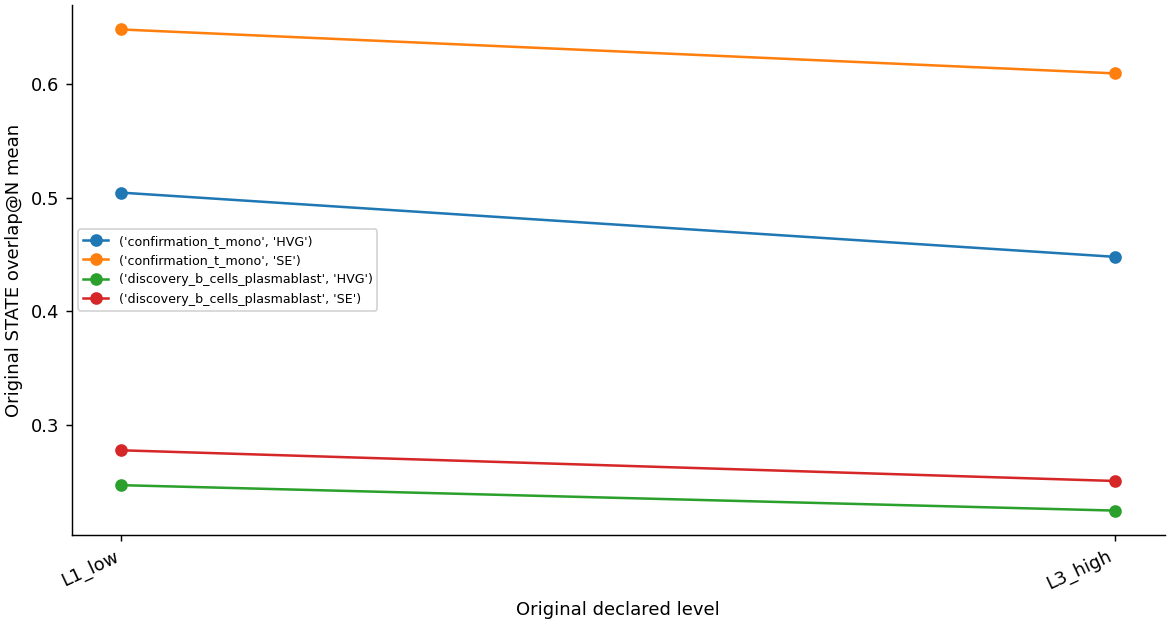

Curves are recalculated means under the original grouping rule. No new confidence bands have been added.


In [5]:
curve=ns.compare_curve('spc_parse_fewshot_ligand_family_support.csv', initial=False)
ns.show_curve(curve)

## Original agent decision and supporting diagnostics

The following records preserve the agent’s actual determination, including rejected candidates and controls. Their historical status labels are shown as recorded.

In [6]:
ns.display_json(rp.CONTINUED/'artifacts/parse_ligand_family_axis_freeze.json')
display(pd.read_csv(rp.COMPUTED/'continued/artifacts/spc_parse_fewshot_ligand_family_support_trends.csv'))
ledger=json.loads((rp.CONTINUED/'spectra_loop_state.json').read_text())
display([x for x in ledger['axes'] if 'PARSE' in x.get('axis_id','')])

```json
{
  "axis_id": "STATE_PARSE_LIGAND_FAMILY_SUPPORT_V1",
  "status": "frozen_before_confirmation",
  "unit": "Parse-PBMC few-shot ligand perturbation in target cell type and representation",
  "similarity": "Count of same prospective ligand/cytokine family perturbations in same-context training set",
  "direction": "STATE performance should degrade as same-family training support decreases",
  "discovery_contexts": [
    "B_Intermediate_Memory",
    "B_Naive",
    "Plasmablast"
  ],
  "confirmation_contexts": [
    "CD14_Mono",
    "CD4_Memory"
  ],
  "target_metric": "overlap_at_N",
  "cutpoints_from_discovery": {
    "<=q33": 0.0,
    "<=q66": 0.0,
    ">q66": "L3_high"
  }
}
```

,spectra_subset,representation,n_levels,n_rows,similarity_monotone_decreasing_when_order_increases,spearman_level_vs_metric,low_similarity_metric_mean,high_similarity_metric_mean,high_minus_low_metric
0,confirmation_t_mono,HVG,2,124,True,-1.0,0.504313,0.447836,-0.056478
1,confirmation_t_mono,SE,2,62,True,-1.0,0.647887,0.609251,-0.038636
2,discovery_b_cells_plasmablast,HVG,2,186,True,-1.0,0.246921,0.224560,-0.022362
3,discovery_b_cells_plasmablast,SE,2,186,True,-1.0,0.277602,0.250604,-0.026997


[{'axis_id': 'STATE_PARSE_LIGAND_FAMILY_SUPPORT_V1',
  'status': 'exploratory_tested',
  'finding': 'Parse ligand-family training support tested as next prospective axis; not used as terminal claim unless it confirms.',
  'artifacts': ['/ewsc/yektefai/spectra_runs/state_generalizability_continued_20260603/artifacts/parse_ligand_family_axis_freeze.json',
   '/ewsc/yektefai/spectra_runs/state_generalizability_continued_20260603/artifacts/spc_parse_fewshot_ligand_family_support.csv',
   '/ewsc/yektefai/spectra_runs/state_generalizability_continued_20260603/artifacts/spc_parse_fewshot_ligand_family_support_trends.csv']}]

All source files, downloaded inputs and historical outputs are checksummed in `original_manifest.json`. The full preliminary candidate screening and download inventory are retained in notebook `00-original-downloads-and-axis-history.ipynb`.